In [59]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
import numpy as np
# import requests

## import data
resale_1999 = pd.read_csv('../data/Resale Flat Prices (Based on Approval Date), 1990 - 1999.csv')
resale_2000 = pd.read_csv('../data/Resale Flat Prices (Based on Approval Date), 2000 - Feb 2012.csv')
resale_2012 = pd.read_csv('../data/Resale Flat Prices (Based on Registration Date), From Mar 2012 to Dec 2014.csv')
resale_2015 = pd.read_csv('../data/Resale Flat Prices (Based on Registration Date), From Jan 2015 to Dec 2016.csv')
resale_2017 = pd.read_csv('../data/Resale flat prices based on registration date from Jan-2017 onwards.csv')

#### abandoned API connection due to rate limit < the largest dataset size, switched to local CSV files

In [60]:

# dataset_ids = {
#     "1990-1999": "d_ebc5ab87086db484f88045b47411ebc5",
#     "2000-2012": "d_43f493c6c50d54243cc1eab0df142d6a",
#     "2012-2014": "d_2d5ff9ea31397b66239f245f57751537",
#     "2015-2016": "d_ea9ed51da2787afaf8e51f827c304208",
#     "2015-2019": "d_8b84c4ee58e3cfc0ece0d773c8ca6abc",
# }


# def load_dataset(period_key, limit=500000):
#   if period_key not in dataset_ids:
#     raise ValueError(
#         f"Invalid period key. Choose from: {list(dataset_ids.keys())}"
#     )

#   resource_id = dataset_ids[period_key]
#   url = f"https://data.gov.sg/api/action/datastore_search?resource_id={resource_id}&limit={limit}"

#   response = requests.get(url)
#   data = response.json()


#   if not data.get("success"):
#     raise Exception(
#         f"Failed to fetch data for '{period_key}'. API Response: {data}"
#     )

#   return pd.DataFrame(data["result"]["records"])


# resale_1999 = load_dataset("1990-1999")
# resale_2000 = load_dataset("2000-2012")
# resale_2012 = load_dataset("2012-2014")
# resale_2015 = load_dataset("2015-2016")
# resale_2019 = load_dataset("2015-2019")

# resale_dfs = {period: load_dataset(period) for period in dataset_ids}

In [61]:
# inspect data from 2012
print(f"Shape of resale_2012: {resale_2012.shape} \n {'#'*10}")

print(f"Info of resale_2012: \n{resale_2012.info()} \n {'#'*10}")

print(f"Columns of resale_2012: \n{resale_2012.columns} \n {'#'*10}")

resale_2012.head(10)

Shape of resale_2012: (52203, 10) 
 ##########
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52203 entries, 0 to 52202
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   month                52203 non-null  object 
 1   town                 52203 non-null  object 
 2   flat_type            52203 non-null  object 
 3   block                52203 non-null  object 
 4   street_name          52203 non-null  object 
 5   storey_range         52203 non-null  object 
 6   floor_area_sqm       52203 non-null  float64
 7   flat_model           52203 non-null  object 
 8   lease_commence_date  52203 non-null  int64  
 9   resale_price         52203 non-null  float64
dtypes: float64(2), int64(1), object(7)
memory usage: 4.0+ MB
Info of resale_2012: 
None 
 ##########
Columns of resale_2012: 
Index(['month', 'town', 'flat_type', 'block', 'street_name', 'storey_range',
       'floor_area_sqm', 'flat_model', '

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price
0,2012-03,ANG MO KIO,2 ROOM,172,ANG MO KIO AVE 4,06 TO 10,45.0,Improved,1986,250000.0
1,2012-03,ANG MO KIO,2 ROOM,510,ANG MO KIO AVE 8,01 TO 05,44.0,Improved,1980,265000.0
2,2012-03,ANG MO KIO,3 ROOM,610,ANG MO KIO AVE 4,06 TO 10,68.0,New Generation,1980,315000.0
3,2012-03,ANG MO KIO,3 ROOM,474,ANG MO KIO AVE 10,01 TO 05,67.0,New Generation,1984,320000.0
4,2012-03,ANG MO KIO,3 ROOM,604,ANG MO KIO AVE 5,06 TO 10,67.0,New Generation,1980,321000.0
5,2012-03,ANG MO KIO,3 ROOM,154,ANG MO KIO AVE 5,01 TO 05,68.0,New Generation,1981,321000.0
6,2012-03,ANG MO KIO,3 ROOM,110,ANG MO KIO AVE 4,01 TO 05,67.0,New Generation,1978,323000.0
7,2012-03,ANG MO KIO,3 ROOM,445,ANG MO KIO AVE 10,01 TO 05,67.0,New Generation,1979,325000.0
8,2012-03,ANG MO KIO,3 ROOM,476,ANG MO KIO AVE 10,11 TO 15,67.0,New Generation,1979,328000.0
9,2012-03,ANG MO KIO,3 ROOM,631,ANG MO KIO AVE 4,01 TO 05,67.0,New Generation,1985,330000.0


### i) Combine datasets

In [62]:

def standardise_columns(df, dataset_name):
    """Standardise column names without discarding any columns."""
    df = df.copy()

    # Use a consistent date column name across all datasets.
    if "month" in df.columns and "year_month" not in df.columns:
        df = df.rename(columns={"month": "year_month"})

    elif "month" in df.columns and "year_month" in df.columns:
        raise ValueError(
            f"{dataset_name} contains both 'month' and 'year_month'. "
            "Resolve this before concatenation."
        )

    if "year_month" not in df.columns:
        raise KeyError(
            f"{dataset_name} has neither 'month' nor 'year_month'."
        )

    return df


def concat_preserving_columns(df1, df2, dataset_name):
    """Concatenate dataframes while preserving all columns."""

    expected_rowcount = len(df1) + len(df2)

    # Keep the union of columns. Missing fields become NaN.
    concatenated_df = pd.concat(
        [df1, df2],
        ignore_index=True,
        sort=False
    )

    actual_rowcount = len(concatenated_df)

    print(
        f"After adding {dataset_name}: "
        f"expected rows = {expected_rowcount:,}, "
        f"actual rows = {actual_rowcount:,}"
    )

    # Retain the original safety check.
    assert actual_rowcount == expected_rowcount, (
        f"Row count mismatch after adding {dataset_name}"
    )

    return concatenated_df

def concat_all_raw_datasets(reference_df=resale_2012):

    # List the datasets explicitly instead of using eval().
    source_dfs = {
        "resale_2012": reference_df,
        "resale_1999": resale_1999,
        "resale_2000": resale_2000,
        "resale_2015": resale_2015,
        "resale_2017": resale_2017
    }

    # Standardise column names on copies of the source data.
    source_dfs = {
        name: standardise_columns(df, name)
        for name, df in source_dfs.items()
    }

    all_columns = set().union(
        *(set(df.columns) for df in source_dfs.values())
    )

    print("\n--- Schema differences ---")
    print(f"Total unique columns across all datasets: {len(all_columns)}")

    for name, df in source_dfs.items():
        missing_columns = sorted(all_columns - set(df.columns))

        if missing_columns:
            print(f"{name} is missing: {missing_columns}")
        else:
            print(f"{name}: no missing columns")

    # Report data-type differences in columns shared by files.
    print("\n--- Data-type differences ---")

    for column in sorted(all_columns):
        dtypes_by_file = {
            name: str(df[column].dtype)
            for name, df in source_dfs.items()
            if column in df.columns
        }

        if len(set(dtypes_by_file.values())) > 1:
            print(f"{column}: {dtypes_by_file}")

    target_df = source_dfs["resale_2012"].copy()

    for name in [
        "resale_1999",
        "resale_2000",
        "resale_2015",
        "resale_2017"
    ]:
        target_df = concat_preserving_columns(
            target_df,
            source_dfs[name],
            name
        )

    return target_df


# Combine the datasets, preserving all columns.
target_df = concat_all_raw_datasets(
    reference_df=resale_2012
)

print("Combined dataset shape:", target_df.shape)


--- Schema differences ---
Total unique columns across all datasets: 11
resale_2012 is missing: ['remaining_lease']
resale_1999 is missing: ['remaining_lease']
resale_2000 is missing: ['remaining_lease']
resale_2015: no missing columns
resale_2017: no missing columns

--- Data-type differences ---
remaining_lease: {'resale_2015': 'int64', 'resale_2017': 'object'}
resale_price: {'resale_2012': 'float64', 'resale_1999': 'int64', 'resale_2000': 'float64', 'resale_2015': 'float64', 'resale_2017': 'float64'}
After adding resale_1999: expected rows = 339,399, actual rows = 339,399
After adding resale_2000: expected rows = 709,050, actual rows = 709,050
After adding resale_2015: expected rows = 746,203, actual rows = 746,203
After adding resale_2017: expected rows = 988,657, actual rows = 988,657
Combined dataset shape: (988657, 11)


In [63]:
# Convert the date column to datetime.
target_df["year_month"] = pd.to_datetime(
    target_df["year_month"],
    errors="coerce"
)

# Report missing or unparseable dates.
invalid_dates = target_df["year_month"].isna().sum()
print(f"Rows with missing or unparseable dates: {invalid_dates:,}")

# Filter to January 2012 through December 2017, inclusive.
target_df = target_df[
    (target_df["year_month"] >= "2012-01-01")
    & (target_df["year_month"] < "2018-01-01")
].copy()

print("\nShape after date filtering:", target_df.shape)


# Investigate duplicate rows

duplicate_count = int(target_df.duplicated().sum())

print(
    "Exact duplicate row occurrences beyond the first copy:",
    f"{duplicate_count:,}"
)

duplicate_rows = target_df[
    target_df.duplicated(keep=False)
].sort_values("year_month")

# Display examples for manual inspection.
display(duplicate_rows.head(30))

# Sort the dataset without removing records.
target_df = target_df.sort_values(
    "year_month"
).reset_index(drop=True)

print("\nFinal shape before deduplication:", target_df.shape)

Rows with missing or unparseable dates: 0

Shape after date filtering: (113053, 11)
Exact duplicate row occurrences beyond the first copy: 445


,year_month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price,remaining_lease
708965,2012-02-01,YISHUN,3 ROOM,108,YISHUN RING RD,01 TO 03,67.0,New Generation,1985,305000.0,NaN
708964,2012-02-01,YISHUN,3 ROOM,108,YISHUN RING RD,01 TO 03,67.0,New Generation,1985,305000.0,NaN
336,2012-03-01,BUKIT BATOK,3 ROOM,212,BT BATOK ST 21,06 TO 10,67.0,New Generation,1985,341000.0,NaN
337,2012-03-01,BUKIT BATOK,3 ROOM,212,BT BATOK ST 21,06 TO 10,67.0,New Generation,1985,341000.0,NaN
4421,2012-04-01,YISHUN,3 ROOM,740,YISHUN AVE 5,06 TO 10,67.0,New Generation,1985,341000.0,NaN
4165,2012-04-01,WOODLANDS,3 ROOM,15,MARSILING LANE,01 TO 05,65.0,Improved,1976,280000.0,NaN
4420,2012-04-01,YISHUN,3 ROOM,740,YISHUN AVE 5,06 TO 10,67.0,New Generation,1985,341000.0,NaN
3260,2012-04-01,JURONG EAST,3 ROOM,303,JURONG EAST ST 32,01 TO 05,67.0,New Generation,1983,330000.0,NaN
3259,2012-04-01,JURONG EAST,3 ROOM,303,JURONG EAST ST 32,01 TO 05,67.0,New Generation,1983,330000.0,NaN
2651,2012-04-01,BUKIT BATOK,3 ROOM,167,BT BATOK WEST AVE 8,01 TO 05,74.0,Model A,1984,333000.0,NaN



Final shape before deduplication: (113053, 11)


### ii) data profiling

In [64]:
# initial profiling 
print('='*10)
print(target_df.shape)
print('='*10)
print(target_df.info())
print('='*10)
print(target_df.describe())
print('='*10)

(113053, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113053 entries, 0 to 113052
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   year_month           113053 non-null  datetime64[ns]
 1   town                 113053 non-null  object        
 2   flat_type            113053 non-null  object        
 3   block                113053 non-null  object        
 4   street_name          113053 non-null  object        
 5   storey_range         113053 non-null  object        
 6   floor_area_sqm       113053 non-null  float64       
 7   flat_model           113053 non-null  object        
 8   lease_commence_date  113053 non-null  int64         
 9   resale_price         113053 non-null  float64       
 10  remaining_lease      57662 non-null   object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(7)
memory usage: 9.5+ MB
None
                          year_month

In [65]:
# null value check (measures)
print("----- null value check (measures) -----")

for column in target_df.columns:
    null_count = target_df[column].isnull().sum()
    print(f"{column}: {null_count} null values")

print('\n')
print("----- null value check (attributes) -----")

# null value check (attributes)
for column in target_df.select_dtypes(include=['object']).columns:
    null_count = target_df[column].isnull().sum()
    print(f"{column}: {null_count} null values")

----- null value check (measures) -----
year_month: 0 null values
town: 0 null values
flat_type: 0 null values
block: 0 null values
street_name: 0 null values
storey_range: 0 null values
floor_area_sqm: 0 null values
flat_model: 0 null values
lease_commence_date: 0 null values
resale_price: 0 null values
remaining_lease: 55391 null values


----- null value check (attributes) -----
town: 0 null values
flat_type: 0 null values
block: 0 null values
street_name: 0 null values
storey_range: 0 null values
flat_model: 0 null values
remaining_lease: 55391 null values


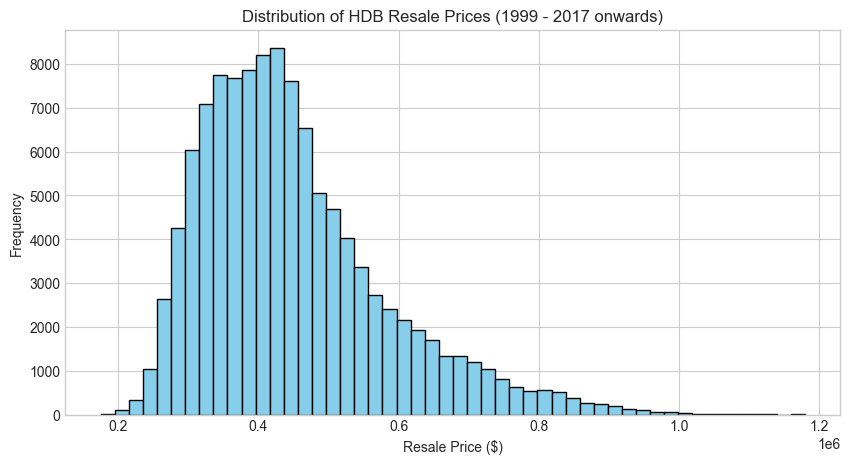

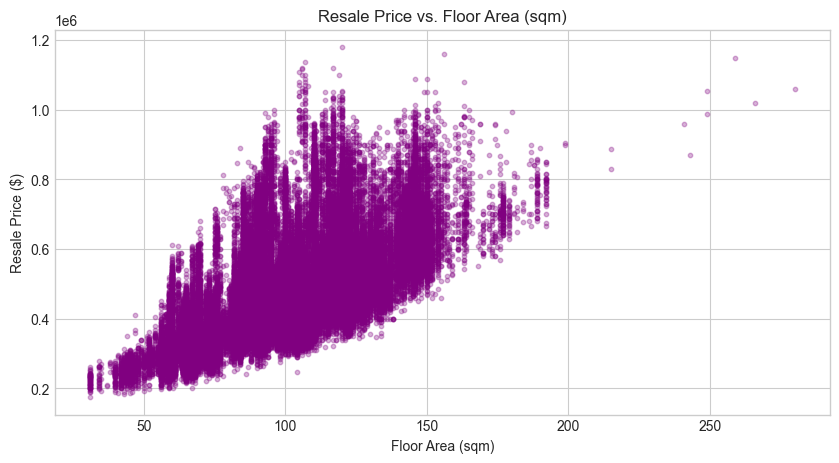

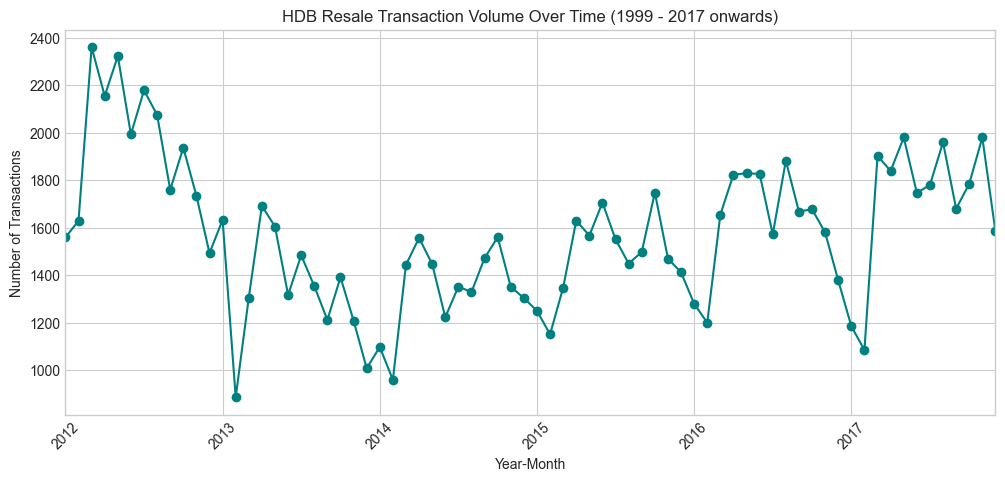

In [66]:
def generate_profiling_charts(df):

  plt.style.use('seaborn-v0_8-whitegrid')

  # 1. Resale Price Distribution
  plt.figure(figsize=(10, 5))
  plt.hist(df['resale_price'], bins=50, color='skyblue', edgecolor='black')
  plt.title('Distribution of HDB Resale Prices (1999 - 2017 onwards)')
  plt.xlabel('Resale Price ($)')
  plt.ylabel('Frequency')
  plt.show()

  # 2. Price vs Floor Area (Scatter Plot)
  plt.figure(figsize=(10, 5))
  plt.scatter(
      df['floor_area_sqm'],
      df['resale_price'],
      alpha=0.3,
      color='purple',
      s=10,
  )
  plt.title('Resale Price vs. Floor Area (sqm)')
  plt.xlabel('Floor Area (sqm)')
  plt.ylabel('Resale Price ($)')
  plt.show()

  # 3. Monthly Transaction Volume Trend
  df['year_month'] = pd.to_datetime(df['year_month']).dt.to_period('M')
  monthly_counts = df.groupby('year_month').size()

  plt.figure(figsize=(12, 5))
  monthly_counts.plot(kind='line', marker='o', color='teal')
  plt.title('HDB Resale Transaction Volume Over Time (1999 - 2017 onwards)')
  plt.xlabel('Year-Month')
  plt.ylabel('Number of Transactions')
  plt.xticks(rotation=45)
  plt.show()
  
generate_profiling_charts(target_df)


In [67]:
# outliers to consider:

# one record with a unusually large floor area
print('Single anomaly for floor_area_sqm: 366.7 sqm')
print(target_df['floor_area_sqm'].sort_values().tail(1))

# transaction spike in mar 1999
print('Transaction spike in march 1999')
print(target_df[target_df['year_month'].dt.year == 1999].groupby('year_month').size().sort_values().tail(5))

Single anomaly for floor_area_sqm: 366.7 sqm
58025    280.0
Name: floor_area_sqm, dtype: float64
Transaction spike in march 1999
Series([], Freq: M, dtype: int64)


In [68]:
def casing_drift_check(df):

    drift_results = {}

    for col in df.columns:
        # Keep non-null string values only
        values = df[col].dropna()
        values = values[values.map(lambda x: isinstance(x, str))]

        # Group values by lowercase representation
        grouped = values.groupby(
            values.map(str.lower),
            sort=False
        ).agg(lambda x: list(pd.unique(x)))

        # Keep only groups with multiple distinct variants
        drift_results[col] = {
            normalized: variants
            for normalized, variants in grouped.items()
            if len(variants) > 1
        }

    return drift_results


drift_results = casing_drift_check(target_df)

drift_results

{'year_month': {},
 'town': {},
 'flat_type': {},
 'block': {},
 'street_name': {},
 'storey_range': {},
 'floor_area_sqm': {},
 'flat_model': {},
 'lease_commence_date': {},
 'resale_price': {},
 'remaining_lease': {}}

### iii) Validate Town, Flat Type, Flat Model, and storey_range using Jan 2012

In [69]:
# jan 2012 golden copy for multi keyset later

jan_2012_df = target_df[target_df['year_month'] == '2012-01'].copy()
print(jan_2012_df.shape)
jan_2012_df.head()

(1559, 11)


,year_month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price,remaining_lease
0,2012-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,01 TO 03,44.0,Improved,1979,257800.0,NaN
1,2012-01,SENGKANG,4 ROOM,185D,RIVERVALE CRES,16 TO 18,85.0,Model A2,2000,417000.0,NaN
2,2012-01,SENGKANG,4 ROOM,185B,RIVERVALE CRES,07 TO 09,85.0,Model A2,2000,398000.0,NaN
3,2012-01,SENGKANG,4 ROOM,259B,COMPASSVALE RD,13 TO 15,85.0,Model A2,2001,440000.0,NaN
4,2012-01,SENGKANG,4 ROOM,110,RIVERVALE WALK,04 TO 06,101.0,Model A,1999,443000.0,NaN


In [70]:
population_df = target_df.copy()
validation_columns = ['town', 'flat_type', 'flat_model', 'storey_range']

jan_2012_reference = jan_2012_df[validation_columns].drop_duplicates().reset_index(drop=True)

def validate_population_against_reference(population_df, reference_df, validation_columns):
    
    validated_master = pd.merge(
        population_df,
        reference_df,
        on=validation_columns,
        how='left',
        indicator=True
    )
    cleaned_master_df = validated_master[validated_master['_merge'] == 'both'].copy().drop(columns=['_merge'])
    quarantined_master_df = validated_master[validated_master['_merge'] == 'left_only'].copy().drop(columns=['_merge'])
    
    print(f"Total Population Records: {population_df.shape[0]}")
    print(f"Total Clean Records: {cleaned_master_df.shape[0]}")
    print(f"Total Quarantined Records: {quarantined_master_df.shape[0]}")
    
    return cleaned_master_df, quarantined_master_df

cleaned_master_df, quarantined_master_df = validate_population_against_reference(population_df, jan_2012_reference, validation_columns)
# the filter is a multi-key filter based on the validation columns

Total Population Records: 113053
Total Clean Records: 78987
Total Quarantined Records: 34066


### iv) Compute remaining lease as of 1 Jan 2027 rounded down to Year and Month

In [71]:
from dateutil.relativedelta import relativedelta

# remaining lease calculation - accounting for leap years 

master_df = cleaned_master_df.copy().drop_duplicates(inplace=False)
master_df['lease_commence_date'] = pd.to_datetime(master_df['lease_commence_date'])



def calculate_remaining_lease(reference_date, df, lease_years=99):
        
        
    reference_date = pd.Timestamp(reference_date).normalize()

    # Convert commencement dates
    df["lease_commence_date"] = pd.to_datetime(
        df["lease_commence_date"], errors="coerce"
    )

    df["expiry_date"] = (
        df["lease_commence_date"]
        + pd.DateOffset(years=lease_years)
    )

    columns = [
        "remaining_years",
        "remaining_months",
        "remaining_days",
    ]

    # Initialize remaining durations as missing values
    df[columns] = pd.DataFrame(
        pd.NA,
        index=df.index,
        columns=columns,
        dtype="Int64",
    )

    # Missing commencement dates remain missing.
    valid = df["expiry_date"].notna()

    # Expired leases have zero remaining duration
    expired = valid & (df["expiry_date"] <= reference_date)
    df.loc[expired, columns] = 0

    # Calculate exact calendar differences only for active leases.
    active = valid & (df["expiry_date"] > reference_date)

    expiry_dates = df.loc[active, "expiry_date"]

    differences = [
        relativedelta(expiry, reference_date)
        for expiry in expiry_dates
    ]

    df.loc[active, columns] = pd.DataFrame(
        [
            (diff.years, diff.months, diff.days)
            for diff in differences
        ],
        index=expiry_dates.index,
        columns=columns,
    )

    return df


master_df = target_df.drop_duplicates().copy()

reference_date = datetime(2027, 1, 1)

master_df = calculate_remaining_lease(
        reference_date=reference_date,
        df=master_df,
        lease_years=99,
)

master_df.head()

,year_month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price,remaining_lease,expiry_date,remaining_years,remaining_months,remaining_days
0,2012-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,01 TO 03,44.0,Improved,1970-01-01 00:00:00.000001979,257800.0,NaN,2069-01-01 00:00:00.000001979,42,0,0
1,2012-01,SENGKANG,4 ROOM,185D,RIVERVALE CRES,16 TO 18,85.0,Model A2,1970-01-01 00:00:00.000002000,417000.0,NaN,2069-01-01 00:00:00.000002000,42,0,0
2,2012-01,SENGKANG,4 ROOM,185B,RIVERVALE CRES,07 TO 09,85.0,Model A2,1970-01-01 00:00:00.000002000,398000.0,NaN,2069-01-01 00:00:00.000002000,42,0,0
3,2012-01,SENGKANG,4 ROOM,259B,COMPASSVALE RD,13 TO 15,85.0,Model A2,1970-01-01 00:00:00.000002001,440000.0,NaN,2069-01-01 00:00:00.000002001,42,0,0
4,2012-01,SENGKANG,4 ROOM,110,RIVERVALE WALK,04 TO 06,101.0,Model A,1970-01-01 00:00:00.000001999,443000.0,NaN,2069-01-01 00:00:00.000001999,42,0,0


### v) Identify anomalous resale prices

In [72]:
master_df = cleaned_master_df.copy().drop_duplicates(inplace=False)

def modified_zscore(group):
    median = group.median()
    mad = np.median(np.abs(group - median))

    # edge case: all prices are identical
    if mad == 0:
        return pd.Series(np.zeros_like(group), index=group.index)

    return pd.Series(0.6745 * (group - median) / mad, index=group.index)
    
def anomalous_resale_prices(df, thresh=4):
    
    df['mod_zscore'] = df.groupby(['town', 'flat_type', 'year_month'])['resale_price'].transform(modified_zscore)
    
    df['price_anomaly'] = df['mod_zscore'].abs() > thresh
    
    # quarantine anomalous and normal
    price_anomalies_df = df[df['price_anomaly']].copy()

    valid_priced_df = df[~df['price_anomaly']].copy().drop(columns=['mod_zscore', 'price_anomaly'])

    print(f"total records: {len(df)}")
    print(f"price anomalies: {len(price_anomalies_df)}")
    print(f"valid priced records: {len(valid_priced_df)}")

    return valid_priced_df, price_anomalies_df
    


valid_priced_df, price_anomalies_df = anomalous_resale_prices(master_df, thresh=3)

# used MAD (Median Absolute Deviation) as it measures variance using median which is robust to large outliers
# Modified zscore is prefered over IQR because IQR doesn't account for dispersion within the tails (truncated vs full distribution)
# at thresh 4, we are capturing extreme outliers (outer 0.0063% of the distribution)

total records: 78668
price anomalies: 2384
valid priced records: 76284


# Data Transformation

### viii) create a column called "resale identifier"

In [73]:
master_data_df = cleaned_master_df.copy()

# rule 1: first character is "S"
first_char = "S"

# rule 2: next 3 digits from block column.
def get_block_digits(df):
    block_digits = df['block'].astype(str) \
        .str.replace(r'\D', '', regex=True) \
        .str.slice(0, 3) \
        .str.zfill(3)
        # get rid of non-digit characters, take first 3 digits, and pad with zeros if necessary
    return block_digits

# rule 3: next 3 digits from first 3 digits of average resale price based on groupings of year-month, town, and flat type.
def get_average_resale_price_digits(df):
    ave_resale_price_digits = df.groupby(['year_month', 'town', 'flat_type'])['resale_price'] \
        .transform('mean') \
        .astype(int) \
        .astype(str) \
        .str.slice(0, 3) \
        .str.zfill(3)
        # take the first 3 digits of the average resale price and pad with zeros if necessary
    return ave_resale_price_digits

# rule 4: next 4 digits are the year_month of the current entry.
def get_year_month_digits(df):
    year_month_digits = df['year_month'].astype(str) \
        .str.replace('-', '', regex=True) \
        .str.slice(2, 6)
        
    return year_month_digits

# rule 5: final character is the first character of the town. 
def get_town_initial(df):
    town_initial = df['town'].astype(str) \
        .str[0] \
        .str.upper()
    return town_initial


master_data_df['resale_identifier_base'] = (
    first_char +
    get_block_digits(master_data_df) +
    get_average_resale_price_digits(master_data_df) +
    get_year_month_digits(master_data_df) +
    get_town_initial(master_data_df)
)

master_data_df['resale_identifier_base']

0         S4062561201A
1         S1854511201S
2         S1854511201S
3         S2594511201S
4         S1104511201S
              ...     
113040    S6672781712H
113042    S0212781712H
113050    S0406591712G
113051    S0076591712G
113052    S8265721712Y
Name: resale_identifier_base, Length: 78987, dtype: object

In [74]:
# rule 6: ensure uniqueness of the identifier

def find_duplicates(df, column):
    identified_duplicates = df[column].value_counts()
    identified_duplicates = identified_duplicates[identified_duplicates > 1]
    print(identified_duplicates)

find_duplicates(master_data_df, 'resale_identifier_base')

# Findings: this is not unique.
    # need to include additional rules to include:
    # bottom floor
    # block characters
    
    
def get_floor_digits(df):
    floor_digits = df['storey_range'].str.replace(r'(\d+)\s+TO\s+(\d+)', r'\1\2', regex=True)
    return floor_digits

def get_block_chars(df):
    block_chars = df['block'].str \
        .replace(r'[^A-Za-z0-9]', '', regex=True)
    return block_chars

test_df = target_df.copy()
test_df['resale_identifier_base'] = (
    first_char +
    get_block_digits(master_data_df) +
    get_average_resale_price_digits(master_data_df) +
    get_year_month_digits(master_data_df) +
    get_floor_digits(master_data_df) +
    get_block_chars(master_data_df) +
    get_town_initial(master_data_df)
)


resale_identifier_base
S2754941208S    9
S2775191304S    7
S3024371501P    7
S2775211310S    7
S4104101711S    7
               ..
S0535541708B    2
S6305091208B    2
S4094101711S    2
S4174471202P    2
S6574111201J    2
Name: count, Length: 7402, dtype: int64


In [75]:
print(find_duplicates(test_df, 'resale_identifier_base'))
test_df[test_df.duplicated('resale_identifier_base', keep=False)].sort_values(
    'resale_identifier_base').head(10)

# I don't want to include resale_price as a identifier, changing approach to indexing duplicates and including it as a identifier

resale_identifier_base
S0444061207010344B      4
S45836117090709458Y     3
S10345912101012103B     3
S56949417080709569H     3
S30236514050709302A     3
                       ..
S12648714061315126DP    2
S64844615040406648AJ    2
S53345317051618533C     2
S60736813080709607A     2
S62930914050709629Y     2
Name: count, Length: 1899, dtype: int64
None


,year_month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price,remaining_lease,resale_identifier_base
52042,2014-10,WOODLANDS,3 ROOM,1,MARSILING DR,07 TO 09,65.0,Improved,1974,256000.0,NaN,S001284141007091W
52114,2014-10,WOODLANDS,3 ROOM,1,MARSILING DR,07 TO 09,65.0,Improved,1974,275000.0,NaN,S001284141007091W
52113,2014-10,WOODLANDS,3 ROOM,1,MARSILING DR,07 TO 09,65.0,Improved,1974,280000.0,NaN,S001284141007091W
49068,2014-08,WOODLANDS,3 ROOM,1,MARSILING DR,04 TO 06,65.0,Improved,1974,268000.0,NaN,S001291140804061W
49071,2014-08,WOODLANDS,3 ROOM,1,MARSILING DR,04 TO 06,76.0,Improved,1974,275000.0,NaN,S001291140804061W
48963,2014-08,GEYLANG,3 ROOM,1,HAIG RD,04 TO 06,59.0,Improved,1982,290000.0,NaN,S001299140804061G
48955,2014-08,GEYLANG,3 ROOM,1,HAIG RD,04 TO 06,59.0,Improved,1982,330000.0,NaN,S001299140804061G
48954,2014-08,GEYLANG,3 ROOM,1,HAIG RD,07 TO 09,59.0,Improved,1982,332388.0,NaN,S001299140807091G
48956,2014-08,GEYLANG,3 ROOM,1,HAIG RD,07 TO 09,59.0,Improved,1982,317000.0,NaN,S001299140807091G
21343,2012-11,WOODLANDS,3 ROOM,1,MARSILING DR,10 TO 12,65.0,Improved,1974,300000.0,NaN,S001322121110121W


In [76]:
# improved approach - we number each sequence and include it as a key before the last character

def get_sequence_digits(df):
    seq_series = df.groupby('resale_identifier_base').cumcount()
    
    # 3 digit padding
    seq_series = seq_series.apply(lambda x: f"{x:03d}")
    
    return seq_series

master_data_df['resale_identifier_base'] = (
    master_data_df['resale_identifier_base'].str.slice(0, -1) +
    get_sequence_digits(master_data_df) +
    master_data_df['resale_identifier_base'].str.slice(-1)
)


print(find_duplicates(master_data_df, 'resale_identifier_base'))

# no duplicates detected.

Series([], Name: count, dtype: int64)
None


### ix) De-identify the identifier column using an irreversible algorithm

In [77]:
# approach - we can use a cryptographic hash function to de-identify the identifier column irreversibly. Something like SHA-256 which serves
    # as a mathematical one-way function.
    # append a secret string before hashing to prevent pre-computed dictionary attacks
    
import hashlib
import os

hashed_master_df = master_data_df.copy()
secret_hash = os.environ.get('SECRET_HASH', 'default_secret')

def generate_hash(identifier, secret):
    
    combined = f"{identifier}{secret}"
    return hashlib.sha256(combined.encode('utf-8')).hexdigest()


hashed_master_df['hashed_resale_identifier'] = (
    hashed_master_df['resale_identifier_base'].apply(lambda x: generate_hash(x, secret_hash))
)


def verify_hash():
    original_unique = master_data_df['resale_identifier_base'].nunique()
    hashed_unique = hashed_master_df['hashed_resale_identifier'].nunique()

    print(f"Total records: {len(hashed_master_df)}")
    print(f"Original unique identifiers: {original_unique}")
    print(f"Hashed unique identifiers: {hashed_unique}")
    print(f"Uniqueness preserved: {original_unique == hashed_unique}")


    print("\Compare Hashed Identifiers:")
    print(hashed_master_df[['resale_identifier_base',
          'hashed_resale_identifier']].head(5))


verify_hash()

Total records: 78987
Original unique identifiers: 78987
Hashed unique identifiers: 78987
Uniqueness preserved: True
\Compare Hashed Identifiers:
  resale_identifier_base                           hashed_resale_identifier
0        S4062561201000A  3e986c5b1f597b1cc62341ed4144cf3c80a734bd01c4fa...
1        S1854511201000S  f5c78ffaf52f78dc280400299179f4a89f8b932b74b1a8...
2        S1854511201001S  8ea63a59480ed27e6e8befc8bc1b36b164d2a62f2d49b5...
3        S2594511201000S  f49fdc03866197dae012a533e55a965509762a00b3bd47...
4        S1104511201000S  ed7ec26307622203998e7f278afc03cd0e2cd7925c7cc7...
